In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [3]:
spectra = pd.read_csv(
    "../data/processed_spectra.csv",
    index_col=0
)

X = spectra.drop(columns=["Label"])
y = spectra["Label"]

In [4]:
from preprocess import (
    smooth_spectra,
    vector_normalize
)

X = smooth_spectra(X)
X = vector_normalize(X)

In [5]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Label"] = y.values

In [6]:
print("Explained Variance Ratio")

print(pca.explained_variance_ratio_)

Explained Variance Ratio
[0.80453951 0.16673982]


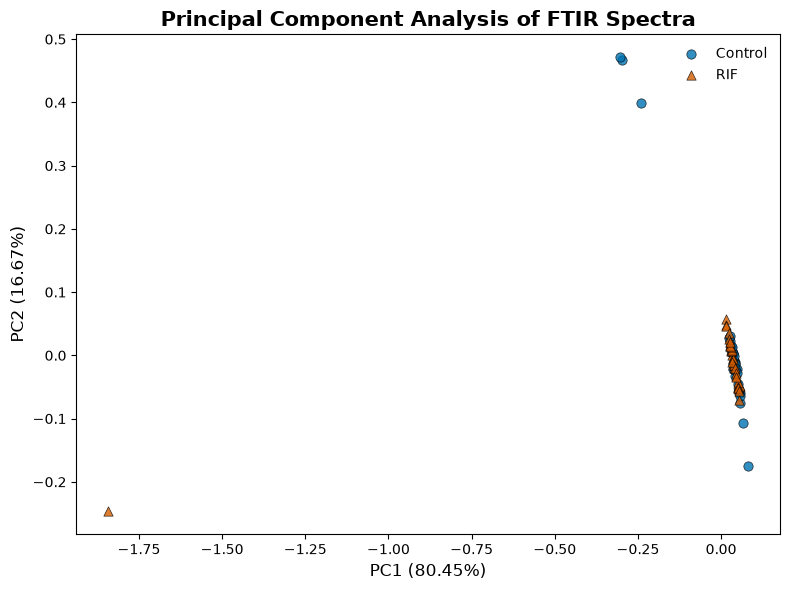

In [7]:
import matplotlib.pyplot as plt

plt.style.use("default")

control_color = "#0072B2"
rif_color = "#D55E00"

plt.figure(figsize=(8, 6))

control_mask = y == 0
rif_mask = y == 1

plt.scatter(
    X_pca[control_mask, 0],
    X_pca[control_mask, 1],
    s=45,
    c=control_color,
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    marker="o",
    label="Control"
)

plt.scatter(
    X_pca[rif_mask, 0],
    X_pca[rif_mask, 1],
    s=45,
    c=rif_color,
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    marker="^",
    label="RIF"
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)",
    fontsize=12
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)",
    fontsize=12
)

plt.title(
    "Principal Component Analysis of FTIR Spectra",
    fontsize=15,
    fontweight="bold"
)

plt.legend(frameon=False)

plt.grid(False)

plt.tight_layout()

plt.savefig(
    "../figures/Figure3_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()